# Student Dropout Prediction: Logistic Regression vs Decision Tree vs Random Forest


## 1. Data Loading & Preparation (shared by all models)

We load the already-prepared train / validation / test files, then separate the features from the target `Dropout`.
The feature columns are already standardised and the categorical variables already encoded in these files.

**Important:** These are the original, imbalanced splits. SMOTE is performed inside each CV training fold using an imblearn Pipeline to prevent leakage.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv('train_final.csv')
val_df = pd.read_csv('val_final.csv')
test_df = pd.read_csv('test_final.csv')

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nOriginal train target distribution:")
print(train_df["Dropout"].value_counts())

Train: (7000, 24)
Validation: (1500, 24)
Test: (1500, 24)

Original train target distribution:
Dropout
0    5352
1    1648
Name: count, dtype: int64


**1.1 Separate Features and Target**

Separate the input columns (X) from the target (y) for each dataset. The same columns are used by every model.

In [ ]:

TARGET = "Dropout"

# Separate features and target
X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]

X_val = val_df.drop(columns=[TARGET])
y_val = val_df[TARGET]

X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]


---
# 2. Logistic Regression

### 2.1 Hyperparameter Tuning

Logistic Regression is a linear model: it estimates dropout probability as a weighted sum of the features passed through a sigmoid.
We tune the regularisation strength `C` (smaller = stronger L2 regularisation, which limits overfitting) with the same Stratified 5-Fold CV and F1 scoring used for the other models.

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

lr_grid = GridSearchCV(
    lr_pipe,
    {"model__C": [0.001, 0.01, 0.1, 0.5, 1, 5, 10]},
    scoring="f1", cv=cv, n_jobs=-1
)
lr_grid.fit(X_train, y_train)

print("Best parameters:", lr_grid.best_params_)
print("Best CV F1-score:", round(lr_grid.best_score_, 4))

Best parameters: {'model__C': 0.001}
Best CV F1-score: 0.574


### 2.2 Training vs Validation Performance & Overfitting Check

We evaluate the tuned model on the training and validation sets and compare the F1-scores. A gap above 0.10 is flagged as possible overfitting.

Note: SMOTE is fitted only within CV training folds by the Pipeline. Compare train/validation performance as a diagnostic; a gap is a warning sign, not a definitive proof by itself.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Best Logistic Regression Model
best_lr = lr_grid.best_estimator_

# Predictions
lr_train_pred = best_lr.predict(X_train)
lr_val_pred = best_lr.predict(X_val)

# Calculate metrics
lr_results = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, lr_train_pred),
        accuracy_score(y_val, lr_val_pred)
    ],
    "Precision": [
        precision_score(y_train, lr_train_pred),
        precision_score(y_val, lr_val_pred)
    ],
    "Recall": [
        recall_score(y_train, lr_train_pred),
        recall_score(y_val, lr_val_pred)
    ],
    "F1-Score": [
        f1_score(y_train, lr_train_pred),
        f1_score(y_val, lr_val_pred)
    ]
})

print(lr_results.round(4))

# Check Overfitting using F1-score
lr_train_f1 = f1_score(y_train, lr_train_pred)
lr_val_f1 = f1_score(y_val, lr_val_pred)

print("\nF1-Score Difference:", round(lr_train_f1 - lr_val_f1, 4))

if lr_train_f1 - lr_val_f1 > 0.10:
    print("Possible Overfitting detected!")
else:
    print("No significant Overfitting detected based on F1-score.")

      Dataset  Accuracy  Precision  Recall  F1-Score
0    Training    0.7449     0.4729  0.7300    0.5740
1  Validation    0.7500     0.4788  0.7025    0.5695

F1-Score Difference: 0.0045
No significant Overfitting detected based on F1-score.


### 2.3 Learning Curve

The learning curve shows training and cross-validation F1 as the amount of training data grows. A large, persistent gap suggests overfitting (high variance); two low, converging curves suggest underfitting (high bias).

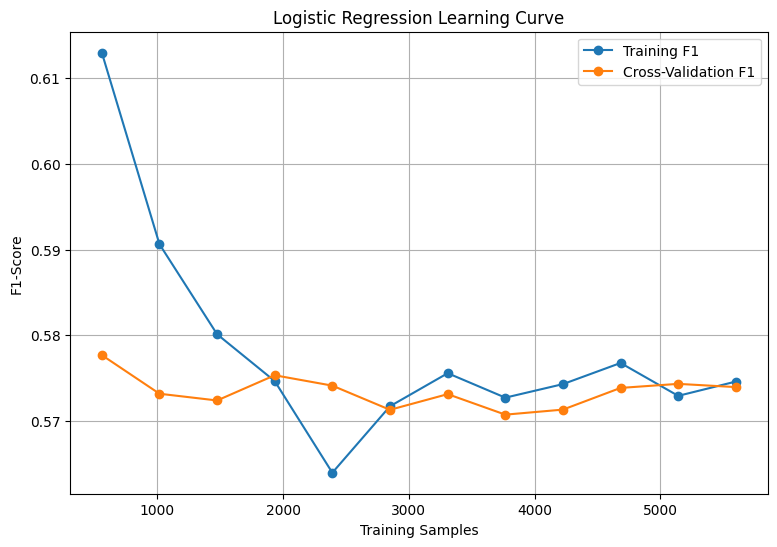

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

best_lr = lr_grid.best_estimator_

lr_train_sizes, lr_train_scores, lr_cv_scores = learning_curve(
    best_lr,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 12),
    n_jobs=-1
)

plt.figure(figsize=(9, 6))

plt.plot(lr_train_sizes, lr_train_scores.mean(axis=1), marker="o", label="Training F1")
plt.plot(lr_train_sizes, lr_cv_scores.mean(axis=1), marker="o", label="Cross-Validation F1")

plt.xlabel("Training Samples")
plt.ylabel("F1-Score")
plt.title("Logistic Regression Learning Curve")
plt.legend()
plt.grid()
plt.show()

### 2.4 Final Model & Test Evaluation

The final model is refit on Train + Validation with the best parameters and evaluated once on the untouched test set.

         precision  recall  f1-score
Stayed        0.90    0.75      0.82
Dropout       0.47    0.72      0.57
Accuracy: 0.75


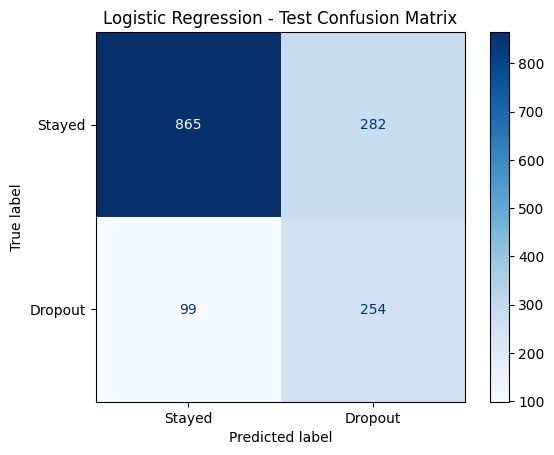

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Refit selected pipeline on original Train + Validation data
final_lr = lr_grid.best_estimator_
final_lr.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

lr_test_pred = final_lr.predict(X_test)
lr_report = classification_report(y_test, lr_test_pred,
    target_names=["Stayed", "Dropout"], output_dict=True)
print(pd.DataFrame(lr_report).T.loc[
    ["Stayed", "Dropout"], ["precision", "recall", "f1-score"]].round(2))
print("Accuracy:", round(lr_report["accuracy"], 2))

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_test_pred, display_labels=["Stayed", "Dropout"], cmap="Blues")
plt.title("Logistic Regression - Test Confusion Matrix")
plt.show()

---
# 3. Decision Tree

### 3.1 Hyperparameter Tuning

A Decision Tree splits the data with a sequence of if/else rules on the features. We tune the split criterion (`gini` / `entropy`), the maximum depth and the minimum samples per leaf, which together control how complex the tree can get.
Same Stratified 5-Fold CV and F1 scoring as the other models.

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dt_pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_grid = GridSearchCV(
    dt_pipe,
    {"model__max_depth": [3, 4, 5, 6, 8, 10,12],
     "model__min_samples_leaf": [5, 10, 20, 50,100,200],
     "model__criterion": ["gini", "entropy"]},
    scoring="f1", cv=cv, n_jobs=-1
)
dt_grid.fit(X_train, y_train)

print("Best parameters:", dt_grid.best_params_)
print("Best CV F1-score:", round(dt_grid.best_score_, 4))

Best parameters: {'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_leaf': 100}
Best CV F1-score: 0.5572


### 3.2 Training vs Validation Performance & Overfitting Check

We evaluate the tuned model on the training and validation sets and compare the F1-scores. A gap above 0.10 is flagged as possible overfitting.

Note: SMOTE is fitted only within CV training folds by the Pipeline. Compare train/validation performance as a diagnostic; a gap is a warning sign, not a definitive proof by itself.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Best Decision Tree Model
best_dt = dt_grid.best_estimator_

# Predictions
y_train_pred = best_dt.predict(X_train)
y_val_pred = best_dt.predict(X_val)

# Calculate metrics
results = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, y_train_pred),
        accuracy_score(y_val, y_val_pred)
    ],
    "Precision": [
        precision_score(y_train, y_train_pred),
        precision_score(y_val, y_val_pred)
    ],
    "Recall": [
        recall_score(y_train, y_train_pred),
        recall_score(y_val, y_val_pred)
    ],
    "F1-Score": [
        f1_score(y_train, y_train_pred),
        f1_score(y_val, y_val_pred)
    ]
})

print(results.round(4))

# Check Overfitting using F1-score
train_f1 = f1_score(y_train, y_train_pred)
val_f1 = f1_score(y_val, y_val_pred)

print("\nF1-Score Difference:", round(train_f1 - val_f1, 4))

if train_f1 - val_f1 > 0.10:
    print("Possible Overfitting detected!")
else:
    print("No significant Overfitting detected based on F1-score.")

      Dataset  Accuracy  Precision  Recall  F1-Score
0    Training    0.7653     0.5011  0.6820    0.5777
1  Validation    0.7527     0.4816  0.6657    0.5589

F1-Score Difference: 0.0189
No significant Overfitting detected based on F1-score.


### 3.3 Learning Curve

The learning curve shows training and cross-validation F1 as the amount of training data grows.

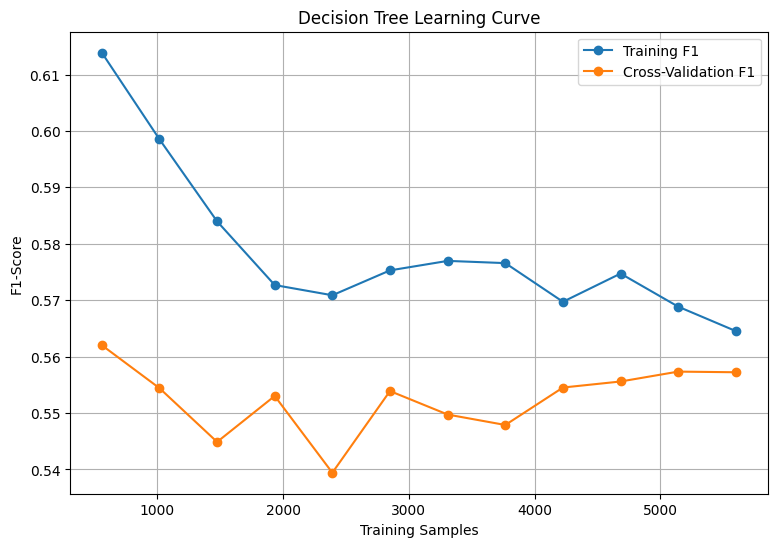

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

best_dt = dt_grid.best_estimator_

train_sizes, train_scores, cv_scores = learning_curve(
    best_dt,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 12),
    n_jobs=-1
)

plt.figure(figsize=(9, 6))

plt.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Training F1")
plt.plot(train_sizes, cv_scores.mean(axis=1), marker="o", label="Cross-Validation F1")

plt.xlabel("Training Samples")
plt.ylabel("F1-Score")
plt.title("Decision Tree Learning Curve")
plt.legend()
plt.grid()
plt.show()

### 3.4 Final Model & Test Evaluation

The final model is refit on Train + Validation with the best parameters and evaluated once on the untouched test set.

         precision  recall  f1-score
Stayed        0.90    0.70      0.79
Dropout       0.44    0.76      0.56
Accuracy: 0.72


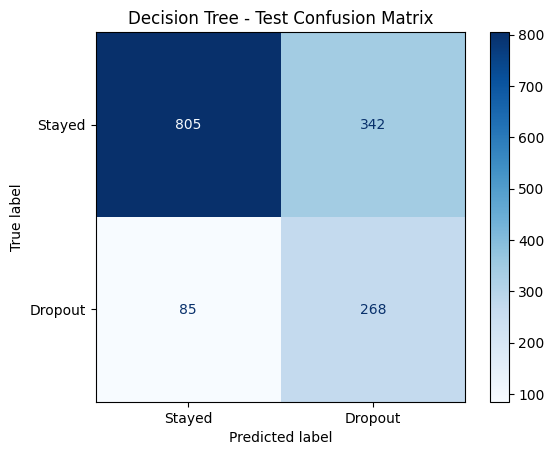

In [ ]:
# Refit selected pipeline on original Train + Validation data
final_dt = dt_grid.best_estimator_
final_dt.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

y_test_pred = final_dt.predict(X_test)
report = classification_report(y_test, y_test_pred,
    target_names=["Stayed", "Dropout"], output_dict=True)
print(pd.DataFrame(report).T.loc[
    ["Stayed", "Dropout"], ["precision", "recall", "f1-score"]].round(2))
print("Accuracy:", round(report["accuracy"], 2))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=["Stayed", "Dropout"], cmap="Blues")
plt.title("Decision Tree - Test Confusion Matrix")
plt.show()

---
# 4. Random Forest

### 4.1 Hyperparameter Tuning

A Random Forest averages many decision trees trained on bootstrap samples with random feature subsets, which reduces the variance of a single tree.
We tune the number of trees, the maximum depth and the minimum samples per leaf, with the same Stratified 5-Fold CV and F1 scoring as the other models.

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42))
])

rf_grid = GridSearchCV(
    rf_pipe,
    {"model__n_estimators": [100, 200],
     "model__max_depth": [3, 5, 7, 8],
     "model__min_samples_leaf": [20, 50, 100]},
    scoring="f1", cv=cv, n_jobs=-1
)
rf_grid.fit(X_train, y_train)

print("Best parameters:", rf_grid.best_params_)
print("Best CV F1-score:", round(rf_grid.best_score_, 4))

Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 20, 'model__n_estimators': 100}
Best CV F1-score: 0.5735


### 4.2 Training vs Validation Performance & Overfitting Check

We evaluate the tuned model on the training and validation sets and compare the F1-scores. A gap above 0.10 is flagged as possible overfitting.

Note: SMOTE is fitted only within CV training folds by the Pipeline. Compare train/validation performance as a diagnostic; a gap is a warning sign, not a definitive proof by itself.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Best Random Forest Model
best_rf = rf_grid.best_estimator_

# Predictions
rf_train_pred = best_rf.predict(X_train)
rf_val_pred = best_rf.predict(X_val)

# Calculate metrics
rf_results = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Accuracy": [
        accuracy_score(y_train, rf_train_pred),
        accuracy_score(y_val, rf_val_pred)
    ],
    "Precision": [
        precision_score(y_train, rf_train_pred),
        precision_score(y_val, rf_val_pred)
    ],
    "Recall": [
        recall_score(y_train, rf_train_pred),
        recall_score(y_val, rf_val_pred)
    ],
    "F1-Score": [
        f1_score(y_train, rf_train_pred),
        f1_score(y_val, rf_val_pred)
    ]
})

print(rf_results.round(4))

# Check Overfitting using F1-score
rf_train_f1 = f1_score(y_train, rf_train_pred)
rf_val_f1 = f1_score(y_val, rf_val_pred)

print("\nF1-Score Difference:", round(rf_train_f1 - rf_val_f1, 4))

if rf_train_f1 - rf_val_f1 > 0.10:
    print("Possible Overfitting detected!")
else:
    print("No significant Overfitting detected based on F1-score.")

      Dataset  Accuracy  Precision  Recall  F1-Score
0    Training    0.7786     0.5208  0.7439    0.6127
1  Validation    0.7600     0.4930  0.6941    0.5765

F1-Score Difference: 0.0362
No significant Overfitting detected based on F1-score.


### 4.3 Learning Curve

The learning curve shows training and cross-validation F1 as the amount of training data grows.

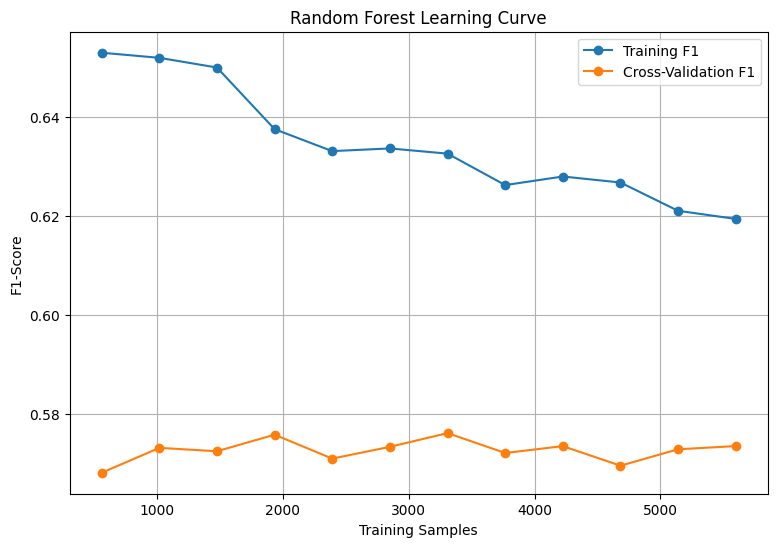

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

best_rf = rf_grid.best_estimator_

rf_train_sizes, rf_train_scores, rf_cv_scores = learning_curve(
    best_rf,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 12),
    n_jobs=-1
)

plt.figure(figsize=(9, 6))

plt.plot(rf_train_sizes, rf_train_scores.mean(axis=1), marker="o", label="Training F1")
plt.plot(rf_train_sizes, rf_cv_scores.mean(axis=1), marker="o", label="Cross-Validation F1")

plt.xlabel("Training Samples")
plt.ylabel("F1-Score")
plt.title("Random Forest Learning Curve")
plt.legend()
plt.grid()
plt.show()

### 4.4 Final Model & Test Evaluation

The final model is refit on Train + Validation with the best parameters and evaluated once on the untouched test set.

         precision  recall  f1-score
Stayed        0.89    0.78      0.83
Dropout       0.48    0.68      0.57
Accuracy: 0.75


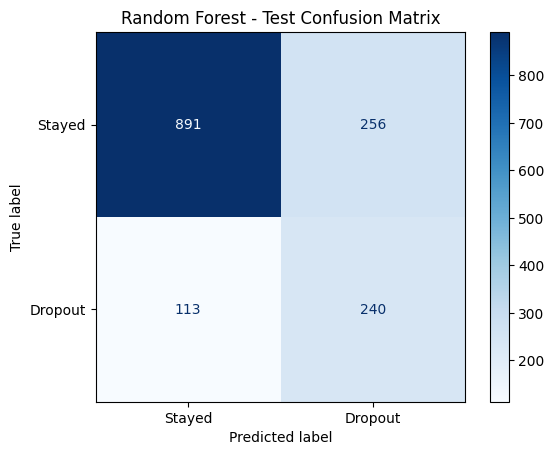

In [ ]:
# Refit selected pipeline on original Train + Validation data
final_rf = rf_grid.best_estimator_
final_rf.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

rf_test_pred = final_rf.predict(X_test)
rf_report = classification_report(y_test, rf_test_pred,
    target_names=["Stayed", "Dropout"], output_dict=True)
print(pd.DataFrame(rf_report).T.loc[
    ["Stayed", "Dropout"], ["precision", "recall", "f1-score"]].round(2))
print("Accuracy:", round(rf_report["accuracy"], 2))

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_test_pred, display_labels=["Stayed", "Dropout"], cmap="Blues")
plt.title("Random Forest - Test Confusion Matrix")
plt.show()

---
# 5. Model Comparison

Compare the three final models using the exact same test examples and metrics. F1-score, precision and recall

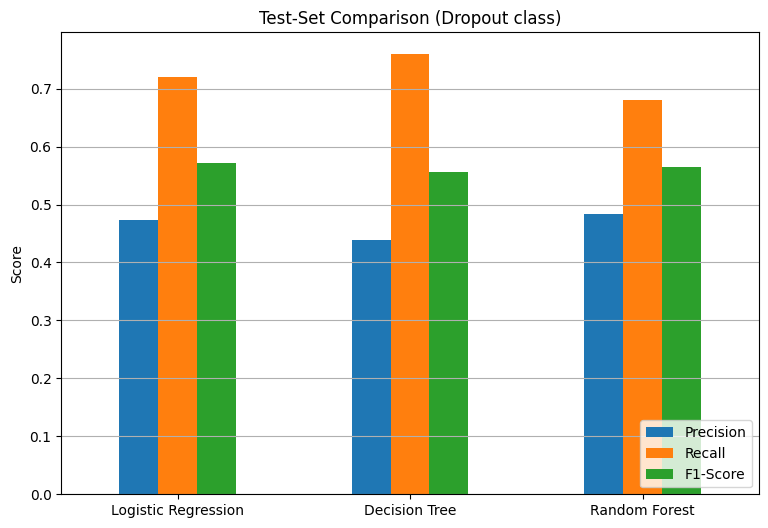

In [ ]:
models = {
    "Logistic Regression": final_lr,
    "Decision Tree": final_dt,
    "Random Forest": final_rf,
}

comparison = pd.DataFrame({
    name: {
        "Precision": precision_score(y_test, m.predict(X_test)),
        "Recall":    recall_score(y_test, m.predict(X_test)),
        "F1-Score":  f1_score(y_test, m.predict(X_test)),
    }
    for name, m in models.items()
}).T

comparison.plot(kind="bar", figsize=(9, 6), rot=0)
plt.ylabel("Score")
plt.title("Test-Set Comparison (Dropout class)")
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

# Compare final test results (use only after model choices are frozen)
#print(comparison.round(3))

# Threshold selection should be done on Validation only, not Test.
# After selecting a threshold based on project priorities, freeze it before final test evaluation.
